# EDA

Análisis exploratorio del dataset Give Me Some Credit (Kaggle, 150k solicitudes). Objetivo: predecir SeriousDlqin2yrs (default a 2 años). Stack SQL: DuckDB.

Identificación de faltantes y outliers, decisiones de tratamiento y hallazgos que guían el feature engineering (02_feature_engineering.ipynb) y la modelización con SHAP (03_modeling_shap.ipynb).

## 1. Configuración y Conexión

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import traceback
import os
import sys
from pathlib import Path
import numpy as np

# Obtiene la ruta absoluta de la raíz del proyecto (subiendo un nivel desde 'notebooks/')
ROOT_DIR = Path().resolve().parent

if str(ROOT_DIR) not in sys.path:
  sys.path.append(str(ROOT_DIR))

In [2]:
from src.data_prep import ingest_csv_to_duckdb
from src.data_prep import CSV_PATH, DB_PATH
from src.data_prep import build_stg

In [3]:
TABLE_NAME = "raw_credit_applications"
    
ingest_csv_to_duckdb(CSV_PATH, DB_PATH, TABLE_NAME)

Tabla 'raw_credit_applications' creada en 'C:\Users\gabri\Documents\gabi\proydata\credit scoring\data\credit_scoring.db' con 150,000 registros.


In [4]:
# conectar a la base de datos desde la carpeta notebooks/
con = duckdb.connect(DB_PATH)

# verificar las tablas disponibles
tables = con.execute("SHOW TABLES;").fetchdf()
display(tables)

,name
0,clean_credit_applications
1,features_credit_applications
2,raw_credit_applications
3,stg_credit_applications


In [5]:
# Ver tipos de datos y columnas de la tabla
schema_df = con.execute("DESCRIBE raw_credit_applications;").fetchdf()
display(schema_df)

,column_name,column_type,null,key,default,extra
0,column00,BIGINT,YES,None,None,None
1,SeriousDlqin2yrs,BIGINT,YES,None,None,None
2,RevolvingUtilizationOfUnsecuredLines,DOUBLE,YES,None,None,None
3,age,BIGINT,YES,None,None,None
4,NumberOfTime30-59DaysPastDueNotWorse,BIGINT,YES,None,None,None
5,DebtRatio,DOUBLE,YES,None,None,None
6,MonthlyIncome,VARCHAR,YES,None,None,None
7,NumberOfOpenCreditLinesAndLoans,BIGINT,YES,None,None,None
8,NumberOfTimes90DaysLate,BIGINT,YES,None,None,None
9,NumberRealEstateLoansOrLines,BIGINT,YES,None,None,None


## 2. Auditoría de Estructura y Tipos de Datos

Hacemos unas consultas para tener una primera impresión de la tabla

In [6]:
def q(sql):
    df = con.execute(sql).fetchdf()
    return df

In [7]:
query_view =  """
    SELECT 
        *
    FROM raw_credit_applications
    LIMIT 10;
"""
q(query_view)

,column00,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120,13,0,6,0,2
1,2,0,0.957151,40,0,0.121876,2600,4,0,0,0,1
2,3,0,0.658180,38,1,0.085113,3042,2,1,0,0,0
3,4,0,0.233810,30,0,0.036050,3300,5,0,0,0,0
4,5,0,0.907239,49,1,0.024926,63588,7,0,1,0,0
5,6,0,0.213179,74,0,0.375607,3500,3,0,1,0,1
6,7,0,0.305682,57,0,5710.000000,NA,8,0,3,0,0
7,8,0,0.754464,39,0,0.209940,3500,8,0,0,0,0
8,9,0,0.116951,27,0,46.000000,NA,2,0,0,0,NA
9,10,0,0.189169,57,0,0.606291,23684,9,0,4,0,2


Claramente 'column00' es un índice y el resto de los datos tienen tipos acordes a sus definiciones.
En esta pequeña muestra se ve que hay valores de 'DebtRatio' muy por arriba de 1, lo cual es anormal, coincidiendo con registros de los cuales se desconoce 'Monthlyincome'. Además, encontramos datos faltantes en 'NumberOfDependents'.

Las features 'Monthlyincome' y 'NumberOfDependents' tienen tipos incorrectos, son VARCHAR cuando deberían ser ambas DOUBLE e INTEGER respectivamente.

Por fuera de esas anomalías, los datos están bien estructurados.

Corregimos esos tipos y reemplacemos los 'NA' por nulos. Además, renombramos las variables estilo snake_case.

Estos cambios dan lugar a la versión stg de nuestra tabla.

In [8]:
try:
    build_stg()
    print("OK build_stg")
except Exception:
    traceback.print_exc()

OK build_stg


In [9]:
# ver tipos de datos y columnas de la tabla
q("DESCRIBE stg_credit_applications;")

,column_name,column_type,null,key,default,extra
0,target,BIGINT,YES,None,None,None
1,revolving_utilization,DOUBLE,YES,None,None,None
2,age,BIGINT,YES,None,None,None
3,times_30_59_dpd,BIGINT,YES,None,None,None
4,debt_ratio,DOUBLE,YES,None,None,None
5,monthly_income,DOUBLE,YES,None,None,None
6,open_credit_lines,BIGINT,YES,None,None,None
7,times_90_dpd,BIGINT,YES,None,None,None
8,real_estate_loans,BIGINT,YES,None,None,None
9,times_60_89_dpd,BIGINT,YES,None,None,None


## 3. Detección de Valores Nulos y Duplicados

Analizamos cuantos duplicados hay

In [10]:
query_duplicados = """
   SELECT * , 
           COUNT(*) AS cantidad_repeticiones
    FROM stg_credit_applications
    GROUP BY ALL
    HAVING COUNT(*) > 1;
"""
df_dup=q(query_duplicados)
display(df_dup)

,target,revolving_utilization,age,times_30_59_dpd,debt_ratio,monthly_income,open_credit_lines,times_90_dpd,real_estate_loans,times_60_89_dpd,dependents,cantidad_repeticiones
0,0,0.0,91,0,0.0,NaN,5,0,0,0,0,3
1,0,0.0,72,0,0.0,NaN,7,0,0,0,0,2
2,0,1.0,28,0,0.0,2200.0,0,0,0,0,0,2
3,0,0.0,85,0,0.0,NaN,3,0,0,0,<NA>,2
4,0,1.0,23,0,0.0,NaN,1,0,0,0,<NA>,3
...,...,...,...,...,...,...,...,...,...,...,...,...
346,0,1.0,28,0,0.0,NaN,1,0,0,0,0,2
347,1,1.0,55,98,0.0,NaN,0,98,0,98,0,2
348,0,0.0,56,0,0.0,NaN,2,0,0,0,0,2
349,0,0.0,27,0,0.0,NaN,2,0,0,0,<NA>,2


Podemos afirmar que hay, al menos, 351 filas con datos idénticos. Verificamos cuantas hay duplicadas en total y a cuantas filas afecta

In [11]:
query_conteo_duplicados = """
    WITH analisis AS (
        SELECT 
            *,
            COUNT(*) AS repeticiones
        FROM stg_credit_applications
        GROUP BY ALL
    )
    SELECT 
        COUNT(CASE WHEN repeticiones > 1 THEN 1 END) AS casos_unicos_duplicados,
        -- El total de filas involucradas en el problema (originales + copias)
        SUM(CASE WHEN repeticiones > 1 THEN repeticiones ELSE 0 END) AS total_filas_afectadas,
        -- Cuántas filas representan copias de otras
        SUM(CASE WHEN repeticiones > 1 THEN repeticiones - 1 ELSE 0 END) AS total_copias_a_eliminar_para_unicidad
    FROM analisis;
"""
q(query_conteo_duplicados)

,casos_unicos_duplicados,total_filas_afectadas,total_copias_a_eliminar_para_unicidad
0,351,960.0,609.0


Dado que no tenemos certeza absoluta de que sean datos duplicados y el número es bastante bajo (menos del 0.5%), se conservamos los datos.

Analizamos cuantos nulos hay por columna

In [12]:
query_null = """
    SELECT 
        SUM(CASE WHEN target IS NULL THEN 1 ELSE 0 END) AS nulos_target,
        SUM(CASE WHEN revolving_utilization IS NULL THEN 1 ELSE 0 END) AS nulos_revolving_utilization,
        SUM(CASE WHEN age IS NULL THEN 1 ELSE 0 END) AS nulos_age,
        SUM(CASE WHEN times_30_59_dpd IS NULL THEN 1 ELSE 0 END) AS nulos_times_30_59_dpd,
        SUM(CASE WHEN debt_ratio IS NULL THEN 1 ELSE 0 END) AS nulos_debt_ratio,
        SUM(CASE WHEN monthly_income IS NULL THEN 1 ELSE 0 END) AS nulos_monthly_income,
        SUM(CASE WHEN open_credit_lines IS NULL THEN 1 ELSE 0 END) AS nulos_open_credit_lines,
        SUM(CASE WHEN times_90_dpd IS NULL THEN 1 ELSE 0 END) AS nulos_times_90_dpd,
        SUM(CASE WHEN real_estate_loans IS NULL THEN 1 ELSE 0 END) AS nulos_real_estate_loans,
        SUM(CASE WHEN times_60_89_dpd IS NULL THEN 1 ELSE 0 END) AS nulos_times_60_89_dpd,
        SUM(CASE WHEN dependents IS NULL THEN 1 ELSE 0 END) AS nulos_dependents    
    FROM stg_credit_applications;
"""
q(query_null)

,nulos_target,nulos_revolving_utilization,nulos_age,nulos_times_30_59_dpd,nulos_debt_ratio,nulos_monthly_income,nulos_open_credit_lines,nulos_times_90_dpd,nulos_real_estate_loans,nulos_times_60_89_dpd,nulos_dependents
0,0.0,0.0,0.0,0.0,0.0,29731.0,0.0,0.0,0.0,0.0,3924.0


Las únicas columnas que tienen nulos son 'dependents', que tiene 3924 (poco menos que 3%), y 'monthly_income', que tiene 29731. La cantidad de nulos en 'dependents' es pequeña mientras que los faltantes en 'monthly_income' son casi el 20%.

## 4. Análisis de la Variable Objetivo (Target / Tasa de Mora)

Analizamos la variable objetivo y la tasa de mora.

In [13]:
query_target = """
    SELECT 
        target, 
        COUNT(*) AS total_registros,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS porcentaje
    FROM stg_credit_applications
    GROUP BY target;
"""
q(query_target)

,target,total_registros,porcentaje
0,0,139974,93.32
1,1,10026,6.68


Observamos que de los 150000 registros de nuestra base de datos poco menos del 7% corresponde a clientes morosos, lo cual indica que tenemos una distribución muy desbalanceado.

## 5. Análisis Univariado

Analizamos cómo es la distribución de la cada variable. A modo de resumen rapido podemos ver:

In [14]:
query_summary="""SUMMARIZE 
                    SELECT  
                        age,
                        dependents,
                        open_credit_lines,
                        real_estate_loans,
                        revolving_utilization,
                        monthly_income,
                        debt_ratio,
                        times_30_59_dpd,
                        times_60_89_dpd,
                        times_90_dpd
                    FROM stg_credit_applications;"""
q(query_summary)


,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,age,BIGINT,0,109,87,52.295206666666665,14.77186586310031,41,52,63,150000,0.00
1,dependents,INTEGER,0,20,13,0.7572222678605657,1.115086071487141,0,0,1,150000,2.62
2,open_credit_lines,BIGINT,0,58,59,8.45276,5.145950989643278,5,8,11,150000,0.00
3,real_estate_loans,BIGINT,0,54,28,1.01824,1.1297709848828512,0,1,2,150000,0.00
4,revolving_utilization,DOUBLE,0.0,50708.0,128924,6.0484380546668435,249.7553706254403,0.029883250305543237,0.15396164274498692,0.5591290784102452,150000,0.00
5,monthly_income,DOUBLE,0.0,3008750.0,13643,6670.221237392844,14384.674215282103,3390.9640094381484,5384.048604628595,8231.906914468018,150000,19.82
6,debt_ratio,DOUBLE,0.0,329664.0,110364,353.0050757638695,2037.81852314436,0.17521894684935396,0.36645145929308565,0.8787650880910748,150000,0.00
7,times_30_59_dpd,BIGINT,0,98,16,0.4210333333333333,4.192781272018331,0,0,0,150000,0.00
8,times_60_89_dpd,BIGINT,0,98,13,0.24038666666666667,4.155179420987224,0,0,0,150000,0.00
9,times_90_dpd,BIGINT,0,98,19,0.26597333333333334,4.169303787594451,0,0,0,150000,0.00


Analicemos más en detalle y visualmente

### Edad ('age')
Para la edad detectamos que hay un valor 0, lo cual no es posible. Veamos si hay otros valores menores a 18 años

In [15]:
query_target = """
    SELECT  
        COUNT(*) AS cantidad
    FROM stg_credit_applications
    WHERE age<19;
"""
q(query_target)

,cantidad
0,1


dado que es un solo dato, lo eliminaremos.

Text(0, 0.5, 'Cantidad de Clientes')

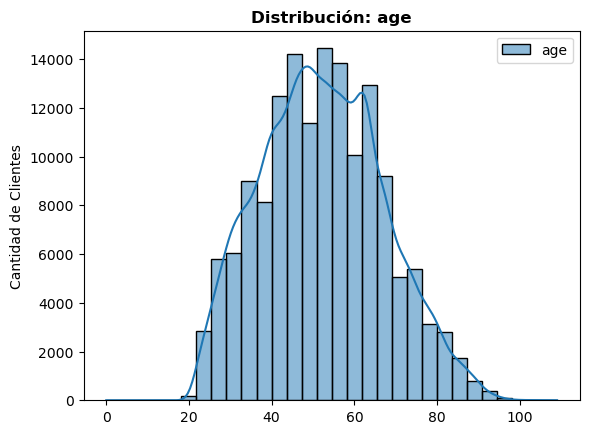

In [16]:
df_age = q("SELECT age FROM stg_credit_applications")
ax = sns.histplot(df_age, kde=True, bins=30)
    

plt.title(f'Distribución: {"age"}', fontsize=12, fontweight='bold')
plt.xlabel('')
plt.ylabel('Cantidad de Clientes')


La distribución por edad es semejante a una distribución normal alrededor de 52 (algo que ya se podía intuír por los cuartiles, media y promedio)

### Familiares a cargo ('dependents')
Para la cantidad de familiares a cargo

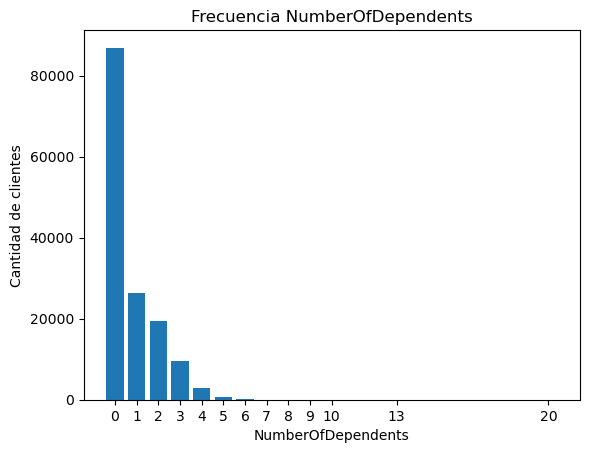

In [17]:
df_dep = q("SELECT dependents FROM stg_credit_applications")

# conteo de frecuencias
frecuencias = df_dep['dependents'].value_counts().sort_index()

# graficar cada número entero con su respectiva frecuencia
plt.bar(frecuencias.index, frecuencias.values)

# forzar a que el eje X muestre todos los números
plt.xticks(frecuencias.index)

plt.title('Frecuencia NumberOfDependents')
plt.xlabel('NumberOfDependents')
plt.ylabel('Cantidad de clientes')

plt.show()


In [18]:
q1 = df_dep['dependents'].quantile(0.25)
q3 = df_dep['dependents'].quantile(0.75)
IQR = q3-q1
print(q3+1.5*IQR)
print((df_dep['dependents']>(q3+1.5*IQR)).sum())

2.5
13336


Observamos una distribución sesgada hacia la derecha con una cola muy larga, en efecto 13336 registros superan q3+1.5IQR. Es decir, casi un 10% de los registros podrían superan ese umbral pero ese umbral es bajo. Por lo cual se aplicará winsorización.

### Lineas de crédito abiertas ('open_credit_lines')
Analizamos cómo se distribuye la poblaciòn en términos de cantidad de líneas abiertas

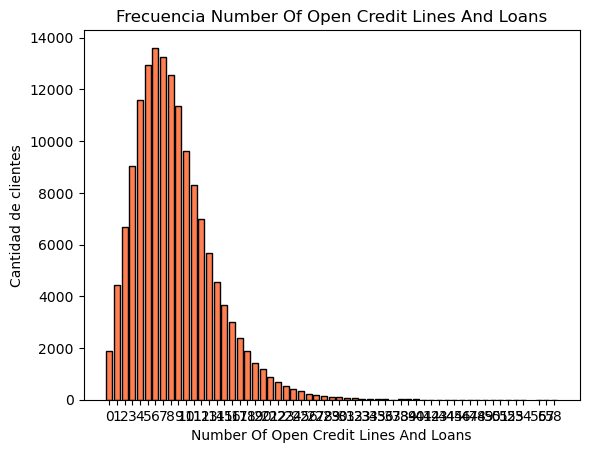

In [19]:
df_open_credit_lines = q("SELECT open_credit_lines FROM stg_credit_applications")

# conteo de frecuencias
frecuencias = df_open_credit_lines['open_credit_lines'].value_counts().sort_index()

# graficar cada número entero con su respectiva frecuencia
plt.bar(frecuencias.index, frecuencias.values, color='coral', edgecolor='black')

# forzar a que el eje X muestre todos los números enteros
plt.xticks(frecuencias.index)

plt.title('Frecuencia Number Of Open Credit Lines And Loans')
plt.xlabel('Number Of Open Credit Lines And Loans')
plt.ylabel('Cantidad de clientes')

plt.show()

In [20]:
q1 = df_open_credit_lines['open_credit_lines'].quantile(0.25)
q3 = df_open_credit_lines['open_credit_lines'].quantile(0.75)
IQR = q3-q1
print(q3+1.5*IQR)
print((df_open_credit_lines['open_credit_lines']>q3+1.5*IQR).sum())

20.0
3980


Observamos una distribución sesgada hacia la derecha y con una larga cola, semejante a una log-normal. En efecto 3980 registros superan q3+1.5IQR. Es decir, más un 2.6% de los registros podrían ser considerados outliers. En pos de conservar los datos se le aplicará winsorización

### Créditos inmobiliarios ('real_stete_loans')
Analizamos cómo se distribuye la poblaciòn en términos de cantidad de créditos inmobiliarios

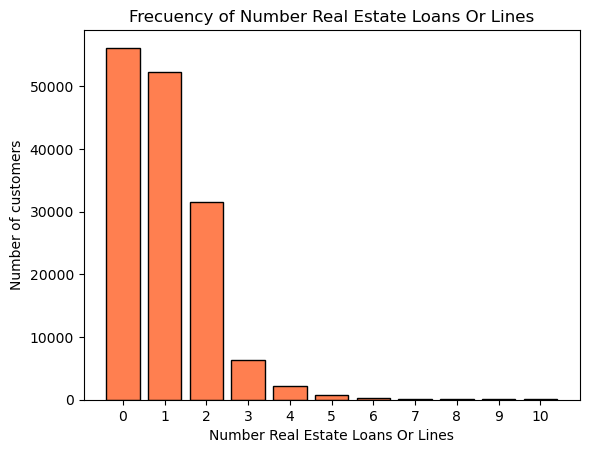

In [21]:
df_real_estate_loans = q("SELECT real_estate_loans FROM stg_credit_applications")

df_filt = df_real_estate_loans[df_real_estate_loans['real_estate_loans'] <= 10]['real_estate_loans']

frecuencies = df_filt.value_counts().sort_index()

plt.bar(frecuencies.index, frecuencies.values, color='coral', edgecolor='black')

plt.xticks(frecuencies.index)

plt.title('Frecuency of Number Real Estate Loans Or Lines')
plt.xlabel('Number Real Estate Loans Or Lines')
plt.ylabel('Number of customers')

plt.show()


In [22]:
q1 = df_real_estate_loans['real_estate_loans'].quantile(0.25)
q3 = df_real_estate_loans['real_estate_loans'].quantile(0.75)
IQR = q3-q1
print(q3+1.5*IQR)
print((df_real_estate_loans['real_estate_loans']>q3+1.5*IQR).sum())

5.0
793


Aquí también observamos una distribución sesgada hacia la derecha y con una larga cola, semejante a una log-normal. Aunque aquí la cantidad de potenciales outliers es menor. Aplicaremos winsorización q3+1.5IQR

### Utilización de crédito revolvente ('revolving_utilization')
Para tasa de uso utilización de crédito revolvente

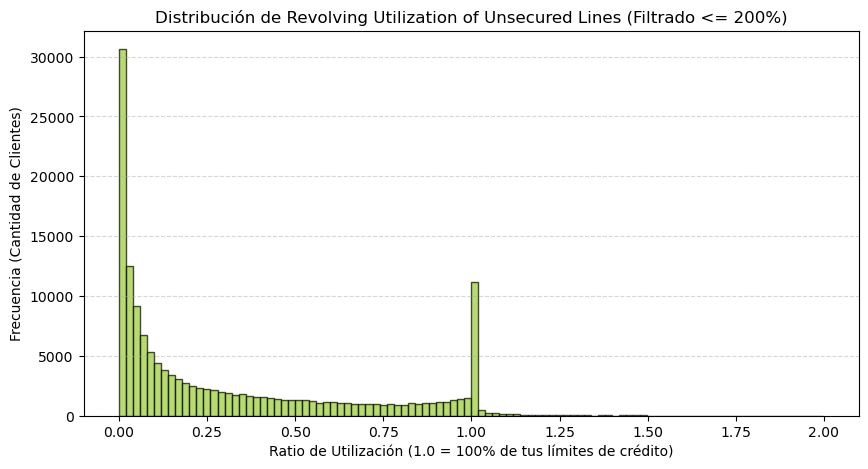

In [23]:
df_revolving_utilization = q("SELECT revolving_utilization FROM stg_credit_applications")

# definimos un límite para la visualización, teniendo en cuenta que son porcentajes usamos 2
limite_vista = 2.0
datos_filtrados = df_revolving_utilization[df_revolving_utilization['revolving_utilization'] <= limite_vista]['revolving_utilization']

# histograma con un número alto de 'bins' para ver el detalle
plt.figure(figsize=(10, 5))
plt.hist(datos_filtrados, bins=100, color='yellowgreen', edgecolor='black', alpha=0.7)

plt.title('Distribución de Revolving Utilization of Unsecured Lines (Filtrado <= 200%)')
plt.xlabel('Ratio de Utilización (1.0 = 100% de tus límites de crédito)')
plt.ylabel('Frecuencia (Cantidad de Clientes)')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


Tenemos una distribución bi-modal, con un primer pico cercano a 0 y otro cercano a 1. Además presenta una cantidad considerable de otuliers

In [24]:
q1 = df_revolving_utilization['revolving_utilization'].quantile(0.25)
q3 = df_revolving_utilization['revolving_utilization'].quantile(0.75)
IQR = q3-q1
print(q3+1.5*IQR)
print((df_revolving_utilization['revolving_utilization']>(q3+1.5*IQR)).sum())

1.35281445575
763


Teniendo en cuenta que es un porcentaje de uso, un valor superior a 1 es extraño pero no imposible ya que puede darse la situación de acumulación de intereses por mora. Para valores mayores a q3+1.5*IQR aplicaremos winsorización.

### Ingresos mensuales ('monthly_income')
Para ingresos mensuales observamos que hay muchos registros con ingreso nulo

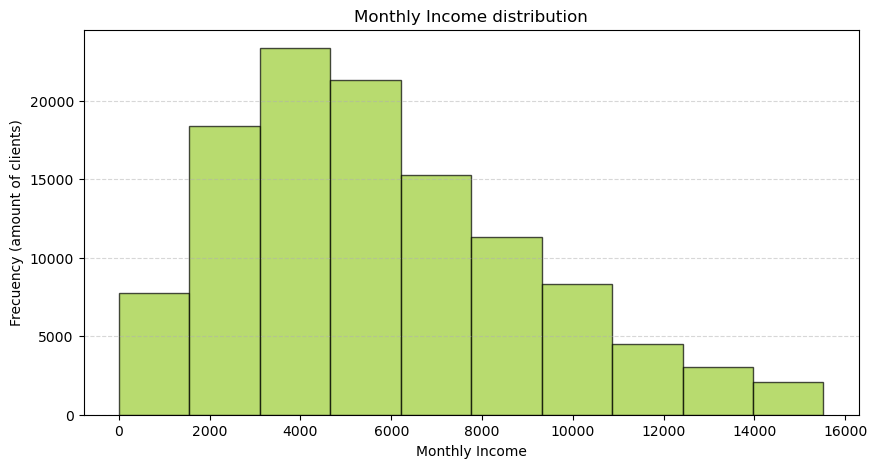

Cantidad de ingresos nulos o ceros: 31365


In [25]:
df_monthly_income = q("SELECT monthly_income FROM stg_credit_applications")

q1=df_monthly_income['monthly_income'].quantile(0.25)
q3=df_monthly_income['monthly_income'].quantile(0.75)
IQR = q3-q1
datos_filtrados = df_monthly_income[df_monthly_income['monthly_income'] <= q3+1.5*IQR]['monthly_income']

# crear el histograma con un número alto de 'bins'
plt.figure(figsize=(10, 5))
plt.hist(datos_filtrados, bins=10, color='yellowgreen', edgecolor='black', alpha=0.7)

plt.title('Monthly Income distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Frecuency (amount of clients)')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print(
    f"Cantidad de ingresos nulos o ceros: "
    f"{((df_monthly_income['monthly_income'].isna()) | (df_monthly_income['monthly_income'] == 0)).sum()}"
)

Aquí también puede observarse una distribución sesgada hacia la derecha. Aplicaremos winsorización q3+1.5IQR
.

### Ratio de endeudamiento ('debt_ratio')
Analizamos el ratio de endeudamiento

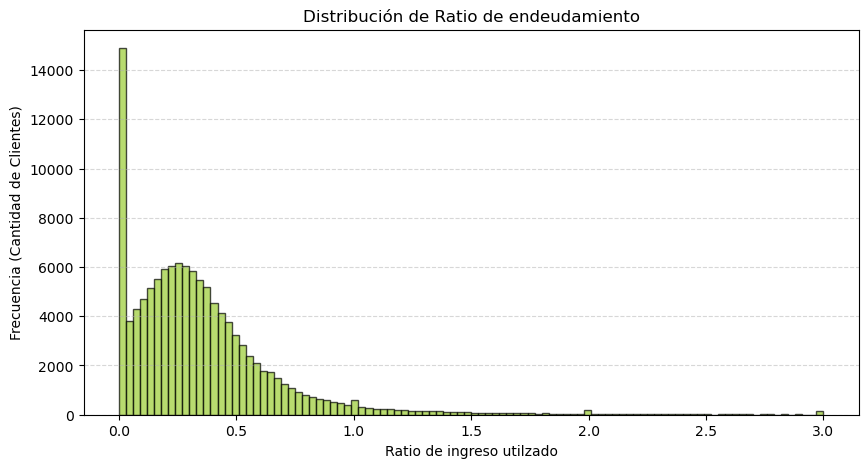

In [26]:
df_debt_ratio = q("SELECT debt_ratio,monthly_income FROM stg_credit_applications")

datos_filtrados = df_debt_ratio[df_debt_ratio['debt_ratio'] <= 3]['debt_ratio']

# crear el histograma con un número alto de 'bins' 
plt.figure(figsize=(10, 5))
plt.hist(datos_filtrados, bins=100, color='yellowgreen', edgecolor='black', alpha=0.7)

plt.title('Distribución de Ratio de endeudamiento')
plt.xlabel('Ratio de ingreso utilzado')
plt.ylabel('Frecuencia (Cantidad de Clientes)')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


Aquí observamos un pico muy alto en torno a 0, lo cual extraño. 

In [27]:
print(df_debt_ratio[df_debt_ratio['debt_ratio'] > 3].count())
print(df_debt_ratio['debt_ratio'].quantile(.99))

debt_ratio        30283
monthly_income     2694
dtype: int64
4979.040000000037


Además, muchos de los valores de alto Ratio de endeudamiento corresponden a registros sin 'monthly_income' o nulo.

In [28]:
df_debt_ratio[(df_debt_ratio['debt_ratio'] > 3) & ((df_debt_ratio['monthly_income'].isna()) | (df_debt_ratio['monthly_income']==0))]

,debt_ratio,monthly_income
6,5710.0,NaN
8,46.0,NaN
14,477.0,0.0
16,2058.0,NaN
32,977.0,NaN
...,...,...
149976,60.0,NaN
149977,349.0,NaN
149984,25.0,NaN
149992,4132.0,NaN


En efecto, de 31365 sin 'monthly_income' 29099 corresponden a 'debt_ratio' altos. Dicho de otro modo: de 30283 'debt_ratio' altos 29099 son datos sin 'monthly_income'. Por lo que hay una evidente relación entre anomalías y faltantes en estas features, pero no resulta evidente cuál es la relación. Esto amerita un tratamiento especial en feature engeneering.

### Historial de mora ('times_30_59_dpd','times_60_89_dpd','times_90_dpd')
Finalmente las tres variables asociadas directamente a mora

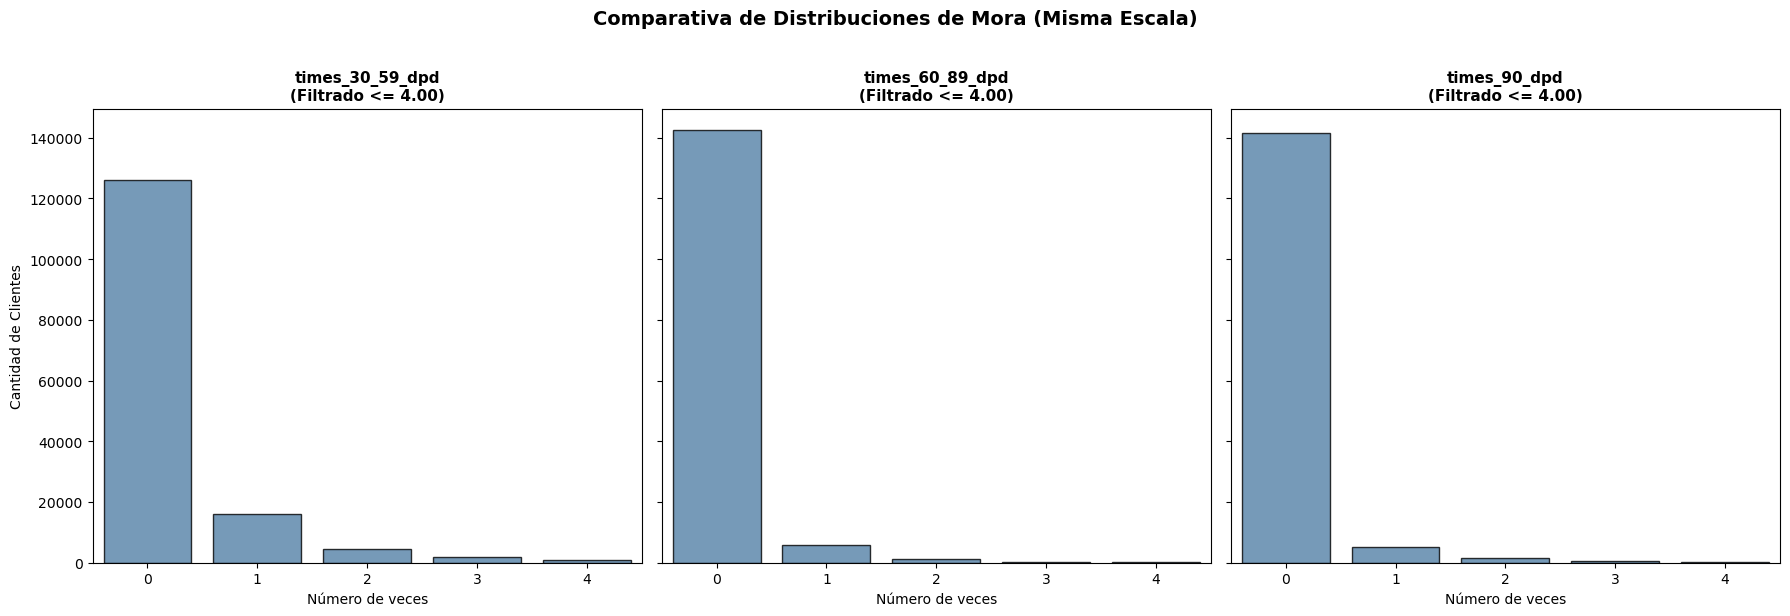

In [29]:
df_times = q("""
    SELECT 
        times_30_59_dpd,
        times_60_89_dpd,
        times_90_dpd
    FROM stg_credit_applications;
""")

variables = ['times_30_59_dpd',
        'times_60_89_dpd',
        'times_90_dpd']

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# determinamos un límite común para el eje X 
max_x_comun = 0

# encontramos el rango del eje X
for col in variables:
    limite_superior = df_times[col].mean() + df_times[col].std()
    max_x_comun = max(max_x_comun, int(limite_superior))

# graficamos uno al lado del otro
for i, col in enumerate(variables):    
    ax = axes[i]
    
    # filtramos
    df_filtrado = df_times[df_times[col] <= max_x_comun]    
    
    # graficamos
    sns.countplot(data=df_filtrado, x=col, color='steelblue', edgecolor='black', alpha=0.8, ax=ax)
    
    ax.set_title(f'{col}\n(Filtrado <= {max_x_comun:.2f})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Número de veces')
    
    # etiqueta al eje Y solo en el primer gráfico porque los demás lo comparten
    if i == 0:
        ax.set_ylabel('Cantidad de Clientes')
    else:
        ax.set_ylabel('')

plt.suptitle('Comparativa de Distribuciones de Mora (Misma Escala)', fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()


Observamos que la mayoría de los clientes no incurrieron en mora superior a 30 días y que la cantidad de veces es decreciente.

In [30]:
print(df_times['times_30_59_dpd'].quantile(.99))
print(df_times['times_60_89_dpd'].quantile(.99))
print(df_times['times_90_dpd'].quantile(.99))
print(df_times[df_times['times_30_59_dpd'] > 4].shape[0])
print(df_times[df_times['times_60_89_dpd'] > 4].shape[0])
print(df_times[df_times['times_90_dpd'] > 4].shape[0])

4.0
2.0
3.0
850
332
582


Dado que para las tres variables el 99% de los datos se agrupan en valores menores a 4, se aplica winsorización con valor máximo  4.

## 8. Análisis Bivariado (Variables vs. Target)


Analizamos la relacion de cada una de las variables con target

### Edad ('age') vs Target

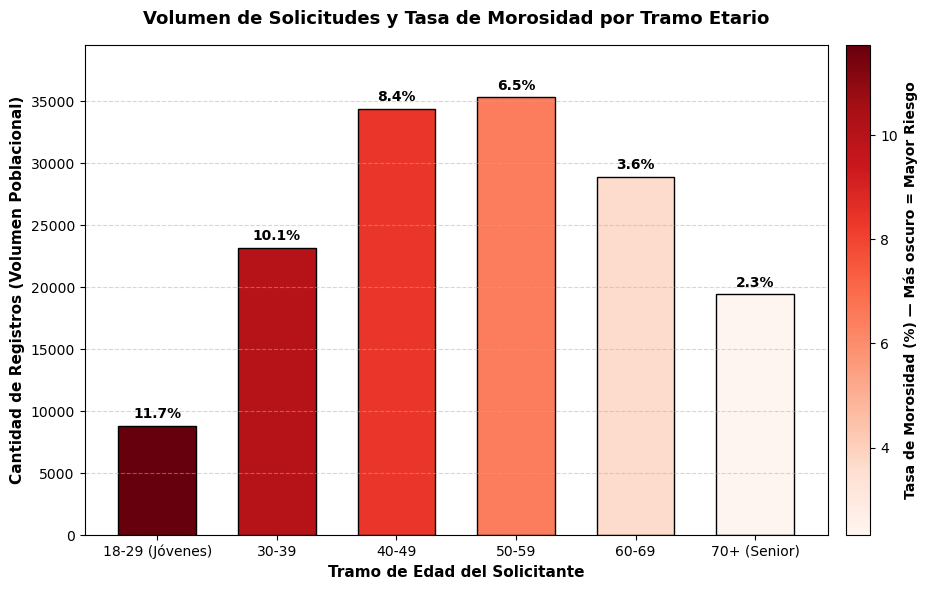

In [31]:
df_t_age = q("""
    SELECT target, age 
    FROM stg_credit_applications 
""")

# agrupar la edad en tramos por décadas
def agrupar_edad(x):
  if x < 30:
    return '18-29 (Jóvenes)'
  elif x < 40:
    return '30-39'
  elif x < 50:
    return '40-49'
  elif x < 60:
    return '50-59'
  elif x < 70:
    return '60-69'
  else:
    return '70+ (Senior)'


df_t_age['Tramo_Edad'] = df_t_age['age'].apply(agrupar_edad)

# orden cronológico deseado
orden_edad = ['18-29 (Jóvenes)', '30-39', '40-49', '50-59', '60-69', '70+ (Senior)']

# calcular el volumen (conteo) y la tasa de morosidad media por tramo
resumen_edad = (
    df_t_age.groupby('Tramo_Edad')
    .agg(
        Conteo_Registros=('target', 'count'),
        Tasa_Mora_Media=('target', 'mean'),
    )
    .reindex(orden_edad)
    .reset_index()
)

resumen_edad['Porcentaje_Mora'] = resumen_edad['Tasa_Mora_Media'] * 100

plt.figure(figsize=(10, 6))

# normalizar los valores de morosidad para mapearlos con una paleta de rojos (Reds)
norm = mcolors.Normalize(
    vmin=resumen_edad['Porcentaje_Mora'].min(),
    vmax=resumen_edad['Porcentaje_Mora'].max(),
)
cmap = cm.Reds
colores = [cmap(norm(val)) for val in resumen_edad['Porcentaje_Mora']]

# Crear el gráfico de barras donde la altura (Y) es el CONTEO de registros
bars = plt.bar(
    resumen_edad['Tramo_Edad'],
    resumen_edad['Conteo_Registros'],
    color=colores,
    edgecolor='black',
    width=0.65,
)

# Añadir el porcentaje exacto de mora como etiqueta sobre cada barra
for bar, pct in zip(bars, resumen_edad['Porcentaje_Mora']):
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height + (max(resumen_edad['Conteo_Registros']) * 0.01),
      f'{pct:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=10,
  )

# Agregar una barra de color (colorbar) orientativa para la escala de riesgo
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label(
    'Tasa de Morosidad (%) — Más oscuro = Mayor Riesgo',
    fontweight='bold',
    fontsize=10,
)

# Estética y títulos ejecutivos
plt.title(
    'Volumen de Solicitudes y Tasa de Morosidad por Tramo Etario',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Tramo de Edad del Solicitante', fontsize=11, fontweight='semibold')
plt.ylabel(
    'Cantidad de Registros (Volumen Poblacional)',
    fontsize=11,
    fontweight='semibold',
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(
    0, max(resumen_edad['Conteo_Registros']) * 1.12
)  #código para dejar espacio a las etiquetas

plt.tight_layout()
plt.show()

Observamos un decrecimiento de la tasa de mora con la edad. Sin embargo, en términos absolutos se registra mucha más mora en rangos etarios entra 40 y 60 años, como se aprecia en esta tabla

In [32]:
resumen_edad

,Tramo_Edad,Conteo_Registros,Tasa_Mora_Media,Porcentaje_Mora
0,18-29 (Jóvenes),8821,0.117334,11.733364
1,30-39,23183,0.100720,10.072036
2,40-49,34377,0.083719,8.371877
3,50-59,35301,0.064531,6.453075
4,60-69,28905,0.036326,3.632590
5,70+ (Senior),19413,0.023180,2.318034


### Familiares a cargo ('dependents') vs Target
Analizamos la relación entre familiares a cargo y el objetivo

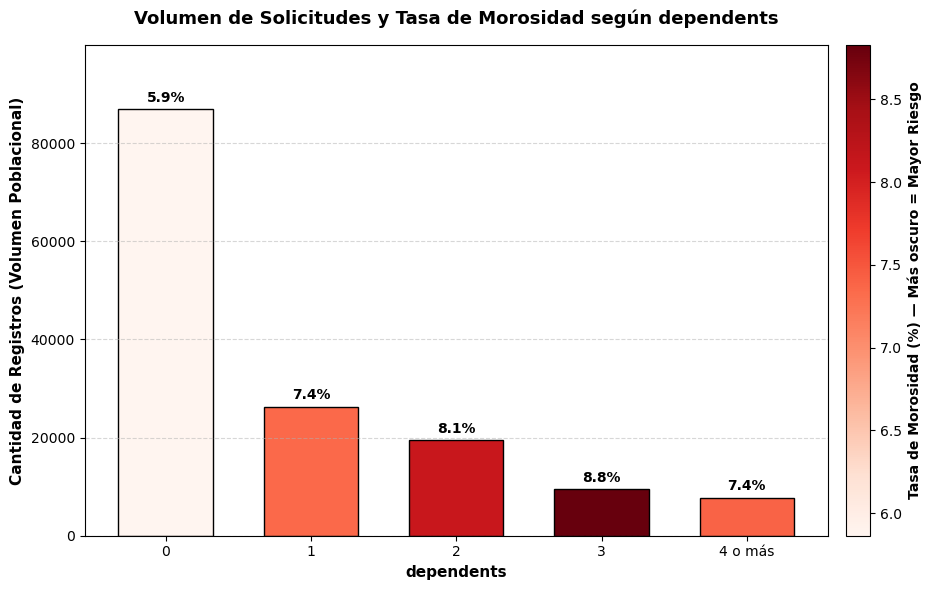

In [33]:
df_dependents = q(
    'SELECT target, dependents FROM stg_credit_applications'
)


# agrupar los valores altos en una categoría "4 o más" 
def agrupar_dependents(x):
  return str(int(x)) if x < 4 else '4 o más'

df_dependents['dependents'] = df_dependents[
    'dependents'
].apply(agrupar_dependents)

# ordenar las categorías correctamente en el eje X
orden = ['0', '1', '2', '3', '4 o más']

# calcular tanto el volumen (conteo) como la tasa de morosidad media por grupo
resumen_re = (
    df_dependents.groupby('dependents')
    .agg(
        Conteo_Registros=('target', 'count'),
        Tasa_Mora_Media=('target', 'mean'),
    )
    .reindex(orden)
    .reset_index()
)

resumen_re['Porcentaje_Mora'] = resumen_re['Tasa_Mora_Media'] * 100

plt.figure(figsize=(10, 6))

# normalizar los valores de morosidad para mapearlos con una paleta secuencial de colores
norm = mcolors.Normalize(
    vmin=resumen_re['Porcentaje_Mora'].min(),
    vmax=resumen_re['Porcentaje_Mora'].max(),
)
cmap = cm.Reds
colores = [cmap(norm(val)) for val in resumen_re['Porcentaje_Mora']]

bars = plt.bar(
    resumen_re['dependents'],
    resumen_re['Conteo_Registros'],
    color=colores,
    edgecolor='black',
    width=0.65,
)

# añadir el porcentaje exacto de mora como etiqueta sobre cada barra
for bar, pct in zip(bars, resumen_re['Porcentaje_Mora']):
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height + (max(resumen_re['Conteo_Registros']) * 0.01),
      f'{pct:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=10,
  )

# agregar la escala de color  para la escala de mora
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label(
    'Tasa de Morosidad (%) — Más oscuro = Mayor Riesgo',
    fontweight='bold',
    fontsize=10,
)

plt.title(
    'Volumen de Solicitudes y Tasa de Morosidad según dependents',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel(
    'dependents',
    fontsize=11,
    fontweight='semibold',
)
plt.ylabel(
    'Cantidad de Registros (Volumen Poblacional)',
    fontsize=11,
    fontweight='semibold',
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(0, max(resumen_re['Conteo_Registros']) * 1.15)

plt.tight_layout()
plt.show()

Observamos una concentración importante de impago en clientes con entre 1 y 3 personas a cargo. Si bien es creciente la proporción de impagos en el intervalo, es decreciente la cantidad de clientes al aumentar la cantidad de personas a cargo.

### Lineas de crédito abiertas ('open_credit_lines') vs Target

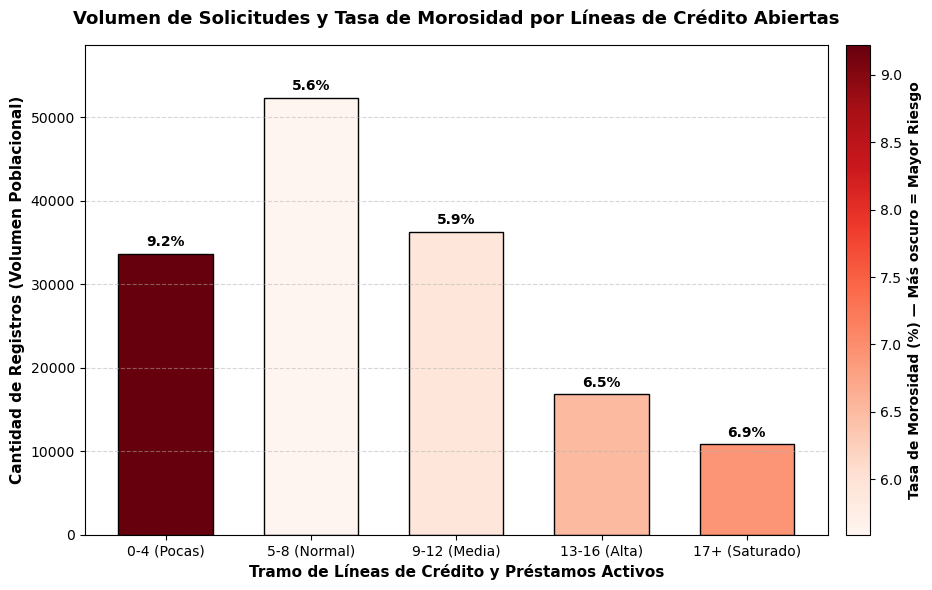

In [34]:
df_open_credit_lines = q(
    'SELECT target, open_credit_lines FROM stg_credit_applications'
)

# crear tramos de comportamiento para las líneas abiertas
def agrupar_lineas(x):
  if x <= 4:
    return '0-4 (Pocas)'
  elif x <= 8:
    return '5-8 (Normal)'
  elif x <= 12:
    return '9-12 (Media)'
  elif x <= 16:
    return '13-16 (Alta)'
  else:
    return '17+ (Saturado)'


df_open_credit_lines['Tramo_Lineas'] = df_open_credit_lines[
    'open_credit_lines'
].apply(agrupar_lineas)

# orden correcto de los tramos en el eje X
orden_tramos = [
    '0-4 (Pocas)',
    '5-8 (Normal)',
    '9-12 (Media)',
    '13-16 (Alta)',
    '17+ (Saturado)',
]

# contar cantidad y tasa de target
resumen_lineas = (
    df_open_credit_lines.groupby('Tramo_Lineas')
    .agg(
        Conteo_Registros=('target', 'count'),
        Tasa_Mora_Media=('target', 'mean'),
    )
    .reindex(orden_tramos)
    .reset_index()
)

resumen_lineas['Porcentaje_Mora'] = resumen_lineas['Tasa_Mora_Media'] * 100

plt.figure(figsize=(10, 6))

# normalizar los valores de morosidad para mapearlos con una paleta de colores 
norm = mcolors.Normalize(
    vmin=resumen_lineas['Porcentaje_Mora'].min(),
    vmax=resumen_lineas['Porcentaje_Mora'].max(),
)
cmap = cm.Reds
colores = [cmap(norm(val)) for val in resumen_lineas['Porcentaje_Mora']]

# crear el gráfico de barras donde la altura (Y) es el CONTEO de registros
bars = plt.bar(
    resumen_lineas['Tramo_Lineas'],
    resumen_lineas['Conteo_Registros'],
    color=colores,
    edgecolor='black',
    width=0.65,
)

# añadir el porcentaje exacto de mora como etiqueta sobre cada barra
for bar, pct in zip(bars, resumen_lineas['Porcentaje_Mora']):
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height + (max(resumen_lineas['Conteo_Registros']) * 0.01),
      f'{pct:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=10,
  )

# agregar una barra de color (colorbar) orientativa para la escala de tasa de mora
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label(
    'Tasa de Morosidad (%) — Más oscuro = Mayor Riesgo',
    fontweight='bold',
    fontsize=10,
)

plt.title(
    'Volumen de Solicitudes y Tasa de Morosidad por Líneas de Crédito Abiertas',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel(
    'Tramo de Líneas de Crédito y Préstamos Activos',
    fontsize=11,
    fontweight='semibold',
)
plt.ylabel(
    'Cantidad de Registros (Volumen Poblacional)',
    fontsize=11,
    fontweight='semibold',
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(0, max(resumen_lineas['Conteo_Registros']) * 1.12)

plt.tight_layout()
plt.show()

Observamos que la mayor morosidad se concentra en los clientes con pocos prestamos activos, siendo además un volumen importante de clientes.

### Créditos inmobiliarios ('real_stete_loans') vs Target
Analizamos la mora de acuerdo a la cantidad de créditos inmobiliarios

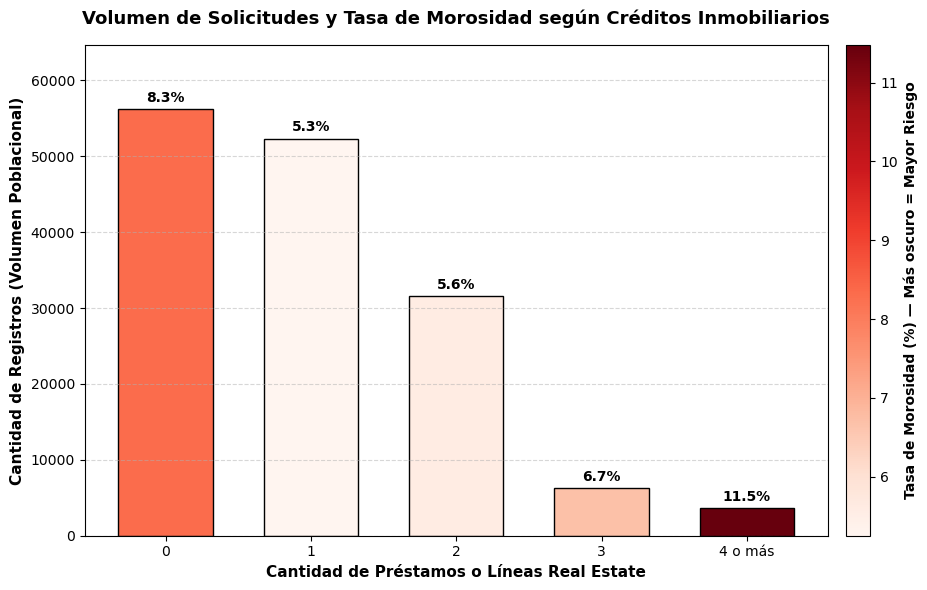

In [35]:
df_real_estate_loans = q(
    'SELECT target, real_estate_loans FROM stg_credit_applications'
)


# agrupar los valores altos en una categoría "4 o más" 
def agrupar_inmobiliarios(x):
  return str(int(x)) if x < 4 else '4 o más'

df_real_estate_loans['Creditos_inmobiliarios'] = df_real_estate_loans[
    'real_estate_loans'
].apply(agrupar_inmobiliarios)

# ordenar las categorías correctamente en el eje X
orden = ['0', '1', '2', '3', '4 o más']

# calcular tanto el volumen (conteo) como la tasa de morosidad media por grupo
resumen_re = (
    df_real_estate_loans.groupby('Creditos_inmobiliarios')
    .agg(
        Conteo_Registros=('target', 'count'),
        Tasa_Mora_Media=('target', 'mean'),
    )
    .reindex(orden)
    .reset_index()
)

resumen_re['Porcentaje_Mora'] = resumen_re['Tasa_Mora_Media'] * 100

plt.figure(figsize=(10, 6))

# normalizar los valores de morosidad para mapearlos con una paleta secuencial de colores
norm = mcolors.Normalize(
    vmin=resumen_re['Porcentaje_Mora'].min(),
    vmax=resumen_re['Porcentaje_Mora'].max(),
)
cmap = cm.Reds
colores = [cmap(norm(val)) for val in resumen_re['Porcentaje_Mora']]

bars = plt.bar(
    resumen_re['Creditos_inmobiliarios'],
    resumen_re['Conteo_Registros'],
    color=colores,
    edgecolor='black',
    width=0.65,
)

# añadir el porcentaje exacto de mora como etiqueta sobre cada barra
for bar, pct in zip(bars, resumen_re['Porcentaje_Mora']):
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height + (max(resumen_re['Conteo_Registros']) * 0.01),
      f'{pct:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=10,
  )

# agregar la escala de color  para la escala de mora
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label(
    'Tasa de Morosidad (%) — Más oscuro = Mayor Riesgo',
    fontweight='bold',
    fontsize=10,
)

plt.title(
    'Volumen de Solicitudes y Tasa de Morosidad según Créditos Inmobiliarios',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel(
    'Cantidad de Préstamos o Líneas Real Estate',
    fontsize=11,
    fontweight='semibold',
)
plt.ylabel(
    'Cantidad de Registros (Volumen Poblacional)',
    fontsize=11,
    fontweight='semibold',
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(0, max(resumen_re['Conteo_Registros']) * 1.15)

plt.tight_layout()
plt.show()

Observamos que la mayor morosidad se concentra en los clientes sin prestamos inmobiliarios o con muchos, siendo el conjunto sin créditos un volumen importante de clientes.

### Utilización de crédito revolvente ('revolving_utilization') vs Target
Analizamos la tasa de mora en comparación con la utilización de crédito revolvente

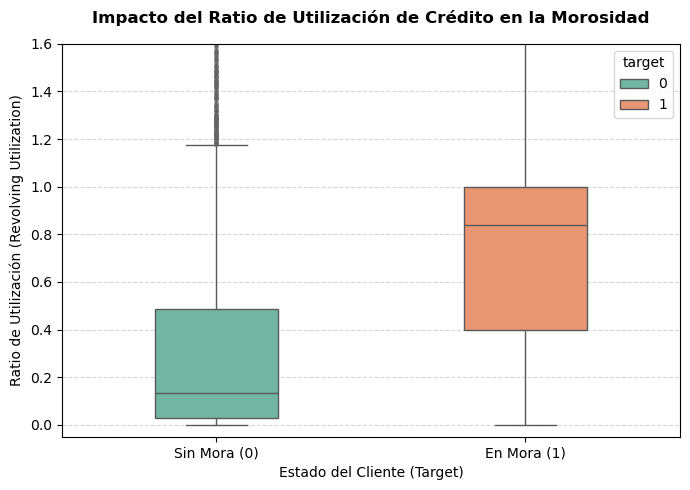

In [36]:
df_revolving_utilization = q(
    'SELECT target, revolving_utilization FROM stg_credit_applications'
)

plt.figure(figsize=(7, 5))

ax = sns.boxplot(
    data=df_revolving_utilization,
    x='target',
    y='revolving_utilization',
    palette='Set2',
    hue='target',
    width=0.4,
    fliersize=3,
    flierprops={'markerfacecolor': '0.4', 'markeredgecolor': 'none', 'alpha': 0.5}
)

plt.ylim(-0.05, 1.6)

plt.title(
    'Impacto del Ratio de Utilización de Crédito en la Morosidad',
    fontsize=12,
    fontweight='bold',
    pad=15
)
plt.xlabel('Estado del Cliente (Target)')
plt.ylabel('Ratio de Utilización (Revolving Utilization)')

# Cambiar el texto del eje X para que sea 100% profesional
plt.xticks([0, 1], ['Sin Mora (0)', 'En Mora (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


Observamos que el Ratio de utilización es radicalmente diferente entre los clientes en mora de los que no

### Ingresos ('monthly_income') vs target
Analizamos como interactuan ingresos y target

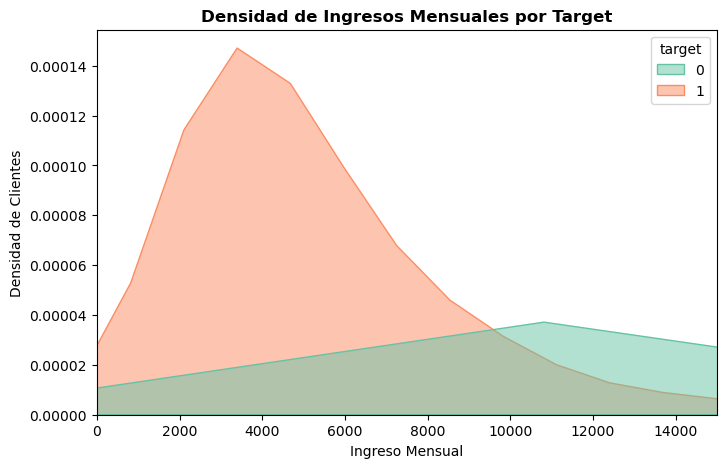

In [37]:
df_monthly_income = q("""
    SELECT target, monthly_income 
    FROM stg_credit_applications 
    WHERE monthly_income IS NOT NULL;
""")

plt.figure(figsize=(8, 5))

# gráfico de densidad con Seaborn
sns.kdeplot(
    data=df_monthly_income,
    x='monthly_income',
    hue='target',
    fill=True,
    common_norm=False,
    palette='Set2',
    alpha=0.5,
)

plt.xlim(0, 15000)

plt.title(
    'Densidad de Ingresos Mensuales por Target', fontsize=12, fontweight='bold'
)
plt.xlabel('Ingreso Mensual')
plt.ylabel('Densidad de Clientes')
plt.show()

Observamos que la distribución de ingresos entre morosos y no morosos es muy diferente, siendo muy concentrada y sesgada hacia la derecha en morosos y menos concentrada y sesgada hacia la izquierda entre no morosos.

### Ratio de endeudamiento ('debt_ratio') vs target
Analizamos la relación entre mora y ratio de endeudamiento

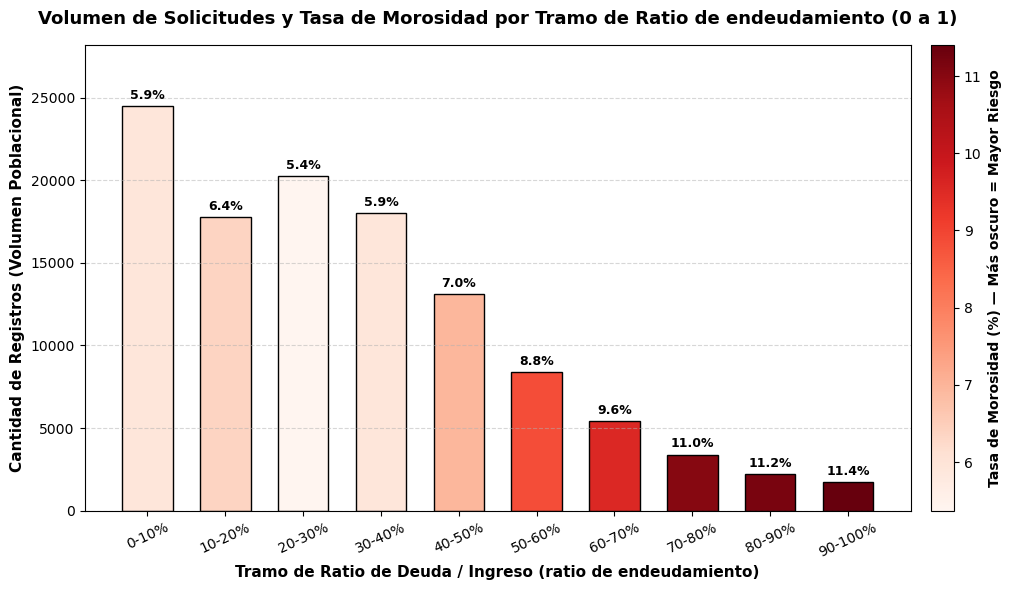

In [38]:
df_debt_ratio = q("""
    SELECT target, debt_ratio 
    FROM stg_credit_applications 
    WHERE debt_ratio <= 3
""")

# definir tramos (bins) de endeudamiento
bins = np.arange(0, 1.1, 0.1)
labels = [f'{int(i*100)}-{int((i+0.1)*100)}%' for i in bins[:-1]]
df_debt_ratio['Tramo_Endeudamiento'] = pd.cut(
    df_debt_ratio['debt_ratio'], bins=bins, labels=labels, include_lowest=True
)

# calcular tanto el volumen (conteo) como la tasa de morosidad media por bin
resumen_debt = (
    df_debt_ratio.groupby('Tramo_Endeudamiento', observed=False)
    .agg(
        Conteo_Registros=('target', 'count'),
        Tasa_Mora_Media=('target', 'mean'),
    )
    .reset_index()
)

resumen_debt['Porcentaje_Mora'] = resumen_debt['Tasa_Mora_Media'] * 100

plt.figure(figsize=(11, 6))

# normalizar los valores de morosidad para mapearlos con una paleta secuencial de tonos
norm = mcolors.Normalize(
    vmin=resumen_debt['Porcentaje_Mora'].min(),
    vmax=resumen_debt['Porcentaje_Mora'].max(),
)
cmap = cm.Reds
colores = [cmap(norm(val)) for val in resumen_debt['Porcentaje_Mora']]

# crear el gráfico de barras donde la altura (Y) es el CONTEO de registros
bars = plt.bar(
    resumen_debt['Tramo_Endeudamiento'],
    resumen_debt['Conteo_Registros'],
    color=colores,
    edgecolor='black',
    width=0.65,
)

# añadir el porcentaje exacto de mora como etiqueta sobre cada barra
for bar, pct in zip(bars, resumen_debt['Porcentaje_Mora']):
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height + (max(resumen_debt['Conteo_Registros']) * 0.01),
      f'{pct:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=9,
  )

# Agregar una barra de color (colorbar) orientativa para la escala de riesgo
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label(
    'Tasa de Morosidad (%) — Más oscuro = Mayor Riesgo',
    fontweight='bold',
    fontsize=10,
)

# Estética y títulos ejecutivos
plt.title(
    'Volumen de Solicitudes y Tasa de Morosidad por Tramo de Ratio de endeudamiento (0 a 1)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel(
    'Tramo de Ratio de Deuda / Ingreso (ratio de endeudamiento)',
    fontsize=11,
    fontweight='semibold',
)
plt.ylabel(
    'Cantidad de Registros (Volumen Poblacional)',
    fontsize=11,
    fontweight='semibold',
)
plt.xticks(rotation=25)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(0, max(resumen_debt['Conteo_Registros']) * 1.15)

plt.tight_layout()
plt.show()

Acá vemos una fuerte correlación positiva entre la tasa de mora por segmento de ratio de deuda y tasa de morosidad.

### Historial de mora ('times_30_59_dpd','times_60_89_dpd','times_90_dpd') vs target
Por último analizamos las tres variables asociadas directamente a mora en relación a target

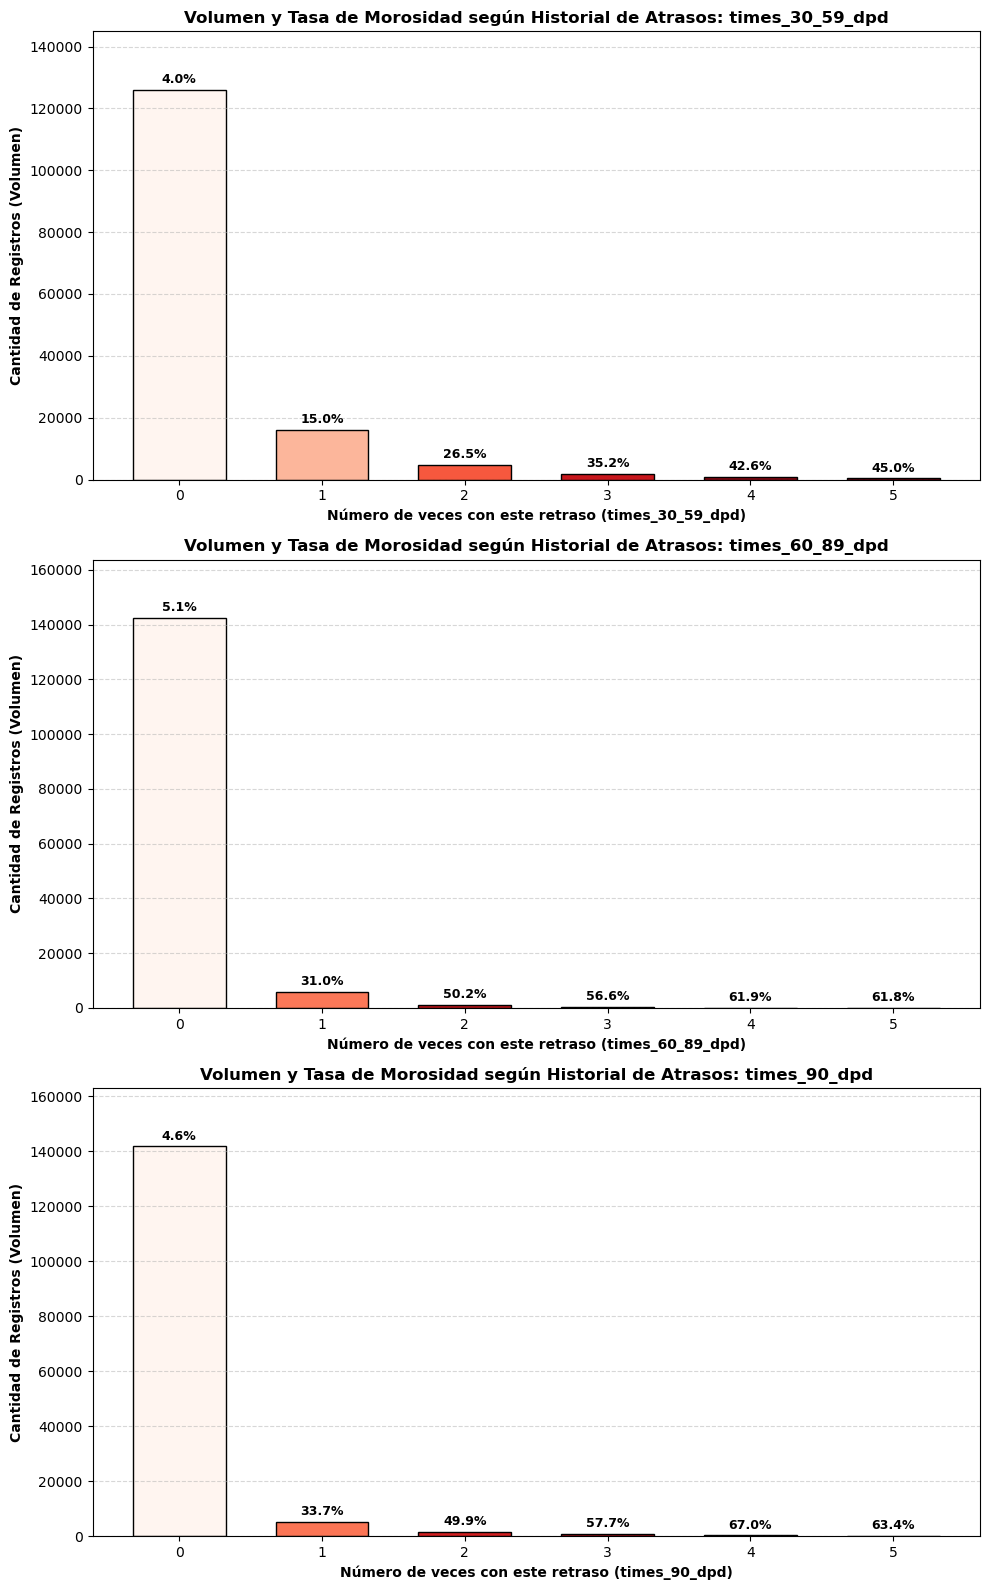

In [39]:
df_atrasos = q("""
    SELECT 
        target,
        times_30_59_dpd,
        times_60_89_dpd,
        times_90_dpd
    FROM stg_credit_applications;
""")

variables = ['times_30_59_dpd', 'times_60_89_dpd', 'times_90_dpd']

plt.figure(figsize=(10, 16))

for i, col in enumerate(variables, 1):
  plt.subplot(3, 1, i)

  # filtrar valores atípicos o códigos de error del dataset original (ej. 96, 98) acotando a <= 5
  df_plot = df_atrasos[df_atrasos[col] <= 5].copy()

  # calcular tanto el volumen (conteo) como la tasa de morosidad media por categoría
  resumen = (
      df_plot.groupby(col)
      .agg(
          Conteo_Registros=('target', 'count'),
          Tasa_Mora_Media=('target', 'mean'),
      )
      .reset_index()
  )
  resumen['Porcentaje_Mora'] = resumen['Tasa_Mora_Media'] * 100

  # cormalizar colores basados en la tasa de mora para usar la paleta de rojos (Reds)
  norm = mcolors.Normalize(
      vmin=resumen['Porcentaje_Mora'].min(),
      vmax=resumen['Porcentaje_Mora'].max(),
  )
  cmap = cm.Reds
  colores = [cmap(norm(val)) for val in resumen['Porcentaje_Mora']]

  # graficar barras con altura = Conteo de Registros
  bars = plt.bar(
      resumen[col],
      resumen['Conteo_Registros'],
      color=colores,
      edgecolor='black',
      width=0.65,
  )

  # añadir las etiquetas del porcentaje exacto de mora arriba de cada barra
  for bar, pct in zip(bars, resumen['Porcentaje_Mora']):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + (max(resumen['Conteo_Registros']) * 0.01),
        f'{pct:.1f}%',
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9,
    )

  plt.title(
      f'Volumen y Tasa de Morosidad según Historial de Atrasos: {col}',
      fontsize=12,
      fontweight='bold',
  )
  plt.xlabel(
      f'Número de veces con este retraso ({col})',
      fontsize=10,
      fontweight='semibold',
  )
  plt.ylabel(
      'Cantidad de Registros (Volumen)', fontsize=10, fontweight='semibold'
  )
  plt.grid(axis='y', linestyle='--', alpha=0.5)
  plt.ylim(0, max(resumen['Conteo_Registros']) * 1.15)

plt.tight_layout()
plt.show()

No hay una relación muy clara entre la cantidad de veces que se experimentó restraso y la tasa de morosidad. Aunque se observa una mayor tasa de morosidad entre quienes incurrieron reiteradas veces en retrasos, siendo en este segmento el tiempo de retraso un indicador positivo para mora

### Matriz de correlacion

Finalmente analizamos la correlacion lineal entre variables

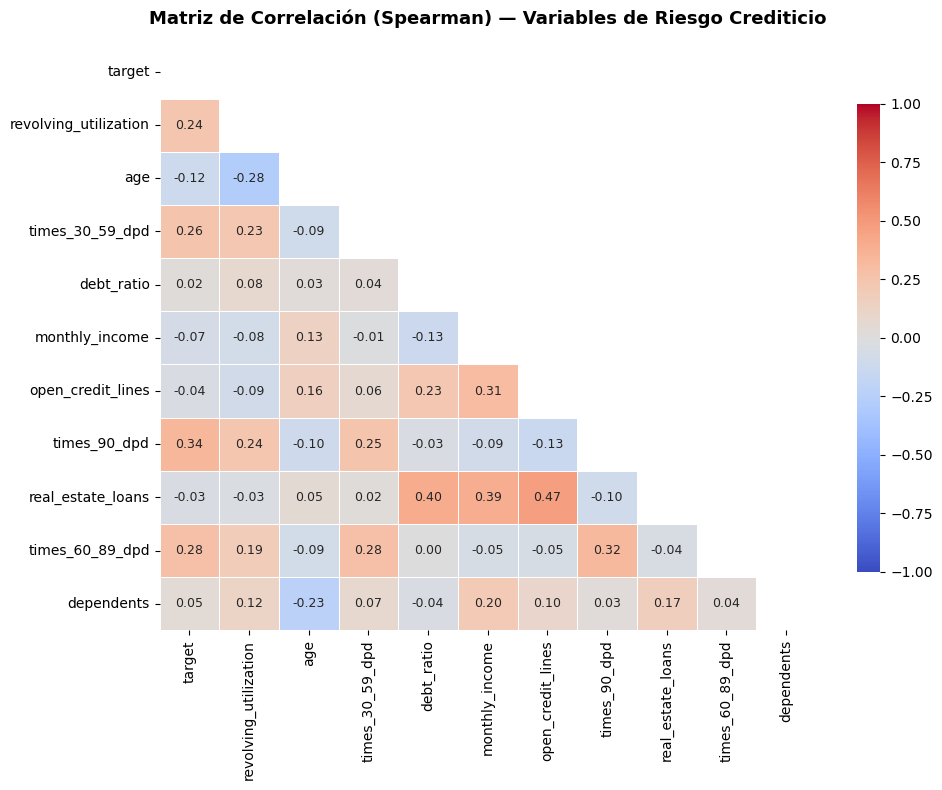

In [40]:
df_corr = q("""
    SELECT 
        target,
        revolving_utilization,
        age,
        times_30_59_dpd,
        debt_ratio,
        monthly_income,
        open_credit_lines,
        times_90_dpd,
        real_estate_loans,
        times_60_89_dpd,
        dependents
    FROM stg_credit_applications
""")

# calcular la matriz de correlación utilizando Spearman
corr_matrix = df_corr.select_dtypes(include=[np.number]).corr(method='spearman')

# ocultar la mitad superior (evita duplicar información simétrica)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',  # Azul = correlación negativa, Rojo = positiva
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    annot_kws={'size': 9},
)

plt.title(
    'Matriz de Correlación (Spearman) — Variables de Riesgo Crediticio',
    fontsize=13,
    fontweight='bold',
    pad=15,
)

plt.tight_layout()
plt.show()

Observamos que las correlaciones mas relevantes con target es de las variables asociadas a retrasos. Además hay cierta correlación entre ellas y entre 'real_estate_loans' con 'monthly_income' (0.40) y 'open_credit_lines'.

# 9. Conclusiones y Decisiones para el Feature Engineering

El dataset cuenta con 150000 datos, de los cuales 10026	(6.68%) representa la clase a identificar, siendo evidente el desbalance.

Se encontraron 609 registros que podrían corresponder a copias a eliminar, dado que no tenemos ninguna evidencia clara al respecto y representan un porcentaje menor, se conservaron.


## Tratamiento de datos faltantes y outliers

Se encontraron valores nulos en 'monthly_income' y 'dependents'. Ambos se imputan con la mediana dentro del pipeline de modelado, ajustado exclusivamente sobre train. 'dependents' se capea a 4 en build_features() (decisión de negocio, no estadística). 'monthly_income' se winsoriza con Q3 + 1.5·IQR en el pipeline, post-imputación, también ajustado sobre train. Se agrega un flag por variable indicando si el dato original era faltante. Las transformaciones de 'monthly_income' se aplican en el orden imputación → winsorización.

Para la variable age se encontró un registro con edad 0, imposible. Se elimina en build_features() mediante WHERE age > 0.

Para los outlier de las variables 'open_credit_lines' y 'real_estate_loans' se aplica winsorización utilizando un límite superior de Q3 + 1.5 * IQR.

Para los outlier de las variables 'times_30_59_dpd', 'times_60_89_dpd' y 'times_90_dpd', se aplica winsorización utilizando limite superior 4 (correspondiente a percentil 99 o superior).

Para los outlier de las variables 'dependents', se aplica winsorización utilizando un límite superior 4.

Para los outliers de la variable 'revolving_utilization' se aplica winsorización utilizando un límite superior 2.

Para los outliers de la variable 'debt_ratio' se aplica winsorización utilizando un límite superior 3.

Dado que muchos de los outliers de 'debt_ratio' coinciden con datos faltantes de 'monthly_income', se agrega un flag que señale cuando se dan ambas condiciones. El flag se computa sobre los valores previos a la imputación y winsorización para preservar la condición original.

## Insights

- Observamos un decrecimiento de la tasa de mora con la edad. Sin embargo, en términos absolutos se registra mucha más mora en rangos etarios entra 40 y 60 años.
- Observamos que la mayor morosidad se concentra en los clientes con pocos préstamos activos, siendo además un volumen considerable de clientes (~9% de clientes).
- En cuanto a los clientes con créditos inmobiliarios, observamos que la mayor morosidad se concentra en los clientes sin créditos o con más de 3.
- Ratio de utilización es una variable que separa bastante fuertemente a los clientes con mora de aquellos que no. La media de los sin mora es aprox 13% y la media de los con mora es de 83%.
- Observamos que la distribución de ingresos entre morosos y no morosos es muy diferente, siendo muy concentrada y sesgada hacia la derecha en morosos y menos concentrada y sesgada hacia la izquierda entre no morosos.
- La tasa de deuda la analizamos por segmentos y observamos una fuerte correlación positiva entre la tasa de endeudamiento y el objetivo. Asimismo se reduce la cantidad de clientes por segmento.
- En cuanto a las variables asociadas a retraso de pago, se puede observar una mayor tasa de morosidad entre quienes incurrieron reiteradas veces en retrasos, siendo en este segmento el tiempo de retraso un indicador positivo para mora



In [41]:
con.close()